In [1]:
import seaborn as sns
import matplotlib.patches as mpatches
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import h5py
import re

root = "/home/lwu/work/NarrativeGenomics/region_narration/code/pipeline/ARCHS4_LW/refining/data_slash_results/"
filename = root + 'archs4_gene_human_v2.1_normalized_LW20230126.h5'
with h5py.File(filename, 'r') as f:
    raw_matrix = f['data/raw_matrix'][:]
    threshold_matrix = f['data/threshold_matrix'][:]
    corrected_matrix = f['data/corrected_matrix'][:] 
    qn_matrix = f['data/qn_matrix'][:]

    gene_names = f['meta/genes/all_gene_names'][:]
    gene_description = f['meta/genes/gene_description'][:]
    all_category_names = f['meta/biosamples/all_biosample_category'][:]
    category_names = f['meta/biosamples/category'][:]

all_category_names = [x.decode('UTF-8') for x in all_category_names]
category_names = [x.decode('UTF-8') for x in category_names]
gene_names = [x.decode('UTF-8') for x in gene_names]
gene_description = [x.decode('UTF-8') for x in gene_description]

category_list  = ["Heart", "Atrium", "Cardiac Muscle Fiber", "Pericardium", "Valve", "Ventricle","HUVEC", 
    "Adipose", "Adipocyte", "Myofibroblast", "Osteoblast", "Stromal Cell", 
    "MG63", "K562", "Bone Marrow", "Chondrocyte", "HT1080", "NHDF",
    "HCT116", "HT29", "RKO", "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", 
    "Small Intestine", "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell",
    "HEPG2", "Alpha Cell", "Beta Cell", "Pancreatic Islet", 
    "GSE81547", "PANC1", "Gastric Epithelial Cell", "Esophagus","Granulocyte", "Neutrophil", "Blymphocyte", 
    "Plasma Cell", "Plasmacytoid Dendritic Cell", 
    "Tlymphocyte", "GSM2679484", "JURKAT", "MT4", "NALM6", "REH", "RPMI8226", "Alveolar", 
    "Dendritic", "Kupffer", "Macrophage", "Macroglia",  "THP1", "U937", "JEG3", "Thymus", 
    "Thymocyte", "Spleen",
    "Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
    "A431", "HACAT", "HNSCC","Skeletal Muscle", "Myoblast", "Airway Smooth Muscle", "Respiratory Smooth Muscle", 
    "Vascular Smooth Muscle", "LHCNM2","Brain", "DAOY", "IMR32", "SKNSH", "Astrocyte", "Cerebellum", "Cerebral Cortex", 
    "Hypothalamus", "Medula", "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", 
    "Thalamus", "Retina", "Motor Neuron", "Sensory Neuron","Lung", "Lung Epithelial", "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE", 
    "Trachea","Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D", 
    "HELA", "Kidney", "Podocyte", "Renal Cortex", "293F", "FLPIN TREX 293", "HEK293", "C42", 
    "DU145", "LNCAP", "PC3", "Ovary", "Granulosa", "Oocyte", "ES2", "SKOV3", "Testis"]

category_dict  = {
    "Cardiovascular System" : ["Heart", "Atrium", "Cardiac Muscle Fiber", 
                               "Pericardium", "Valve", "Ventricle",
                               "HUVEC"], 
    
    "Connective Tissue" : ["Adipose", "Adipocyte", "Myofibroblast", "Osteoblast", "Stromal Cell", 
                           "MG63", "K562", "Bone Marrow", "Chondrocyte", "HT1080", "NHDF"],

    "Digestive System": ["HCT116", "HT29", "RKO", "Colon", "Colonic Muscosa", "Intestinal Epithelial Cell", 
                         "Small Intestine", "Liver", "Hepatic Stellate Cell", "Hepatocyte", "Primary Liver Cell",
                         "HEPG2", "Alpha Cell", "Beta Cell", "Pancreatic Islet", 
                         "GSE81547", "PANC1", "Gastric Epithelial Cell", "Esophagus"],
    
    "Immune System" : ["Granulocyte", "Neutrophil", "Blymphocyte", "Plasma Cell", "Plasmacytoid Dendritic Cell", 
                       "Tlymphocyte", "GSM2679484", "JURKAT", "MT4", "NALM6", "REH", "RPMI8226", "Alveolar", 
                       "Dendritic", "Kupffer", "Macrophage", "Macroglia",  "THP1", "U937", "JEG3", "Thymus", 
                       "Thymocyte", "Spleen"],
    
    "Integumentary System" : ["Skin", "Basal Cell", "Fibroblast", "Hair Follicle", "Keratinocyte", "Melanocyte",
                              "A431", "HACAT", "HNSCC"], 
    
    "Muscular System" : ["Skeletal Muscle", "Myoblast", "Airway Smooth Muscle", "Respiratory Smooth Muscle", 
                         "Vascular Smooth Muscle", "LHCNM2"], 
    
    "Nervous System" : ["Brain", "DAOY", "IMR32", "SKNSH", "Astrocyte", "Cerebellum", "Cerebral Cortex", 
                        "Hypothalamus", "Medula", "Midbrain", "Neuron", "Oligodendrocyte", "Pons", "Spinal Cord", 
                        "Thalamus", "Retina", "Motor Neuron", "Sensory Neuron"], 
    
    "Respiratory System" : ["Lung", "Lung Epithelial", "A549", "H1299", "IMR90", "MRC5", "NCIH460", "NHBE", 
                            "Trachea"], 
    
    "Urogenital System" : ["Breast", "Mammary Gland", "MCF7", "MCF10", "MDAMB231", "MDAMB468", "SKBR3", "T47D", 
                           "HELA", "Kidney", "Podocyte", "Renal Cortex", "293F", "FLPIN TREX 293", "HEK293", "C42", 
                           "DU145", "LNCAP", "PC3", "Ovary", "Granulosa", "Oocyte", "ES2", "SKOV3", "Testis"]
}

# Master User Input Variables 

In [133]:
# Get the index of "MYH1" in the gene_names list

# gene_name = "MYH1"; muscle
# AMY1A; digestion - not clear
# MMP9; immune
# GABARAP; supposed digestive 
# TCF12; stem cells 
# SFTPC; lung

gene_name = "SFTPC"
gene_index = gene_names.index(gene_name)


---
# RAW

In [134]:
# Extract the indexed row from the raw_matrix, WILL NEED TO CHANGE FOR OTHER MATRIXES
raw_gene_data = raw_matrix[gene_index]

In [135]:
# Functions

def get_gene_category_averages(gene_data, category_dict, categories):
    result = {}
    for category, values in category_dict.items():
        matching_indices = [i for i, name in enumerate(categories) if name in values]
        category_values = gene_data[matching_indices]
        average_value = np.mean(category_values)
        result[category] = [average_value]

    return result

def convert_to_matrix(dictionary):
    values_array = np.array(list(dictionary.values()))
    return values_array.flatten()

def perform_ooe(gene_data, geneset_catAvg_matrix):
    # Calculate the average of geneset_catAvg_matrix
    avg = sum(geneset_catAvg_matrix) / len(geneset_catAvg_matrix)
    
     
    # Divide each element in raw_gene_data by the average
    ooe_values = [gene_value / avg for gene_value in raw_gene_data]
    
# OOE but with an additional log2 that I later realized is not needed (we already did log2 during QN processing)
#     # Divide each element in raw_gene_data by the average and apply log2
#     ooe_values = [math.log2(gene_value / avg) for gene_value in gene_data]
    
    return ooe_values

def get_gene_cat_matrix(data, category_dict, categories):
    result = []
    for category, values in category_dict.items():
        temp = []
        for value in values:
            temp.extend([data[i] for i, cat in enumerate(categories) if cat == value])
        result.append(temp)
    return result

def get_filtered_matrix_enrichment_values(gene_data, category_dict, categories):
    # Calculate Geneset Category Averages
    geneset_catAvg_dict = get_gene_category_averages(gene_data, category_dict, categories)
    print("Geneset Category Averaged - Dict Form:")
    print()

    geneset_catAvg_matrix = convert_to_matrix(geneset_catAvg_dict)
    print("Dict to Matrix")
    print()

    # Perform OOE
    ooe_data = perform_ooe(gene_data, geneset_catAvg_matrix)
    print("OOE Matrix")
    print()
    
    # Get System Averages of OOE 
    cat_ooe_matrix = get_gene_cat_matrix(ooe_data, category_dict, categories) # (aka: get_gene_cat_ooe_matrix)
    
    return cat_ooe_matrix

# Calculate Category RAW Matrix
cat_RAW_matrix = get_gene_cat_matrix(raw_gene_data, category_dict, all_category_names)
print("Category RAW Matrix")
print("------------------------\n")

raw_cat_ooe_matrix = get_gene_cat_matrix(raw_gene_data, category_dict, all_category_names) # (aka: get_gene_cat_ooe_matrix)
print("Raw Category OOE Matrix")
print()


Category RAW Matrix
------------------------

Raw Category OOE Matrix



# Plot for Raw - Individual System Boxplot

In [136]:
# IMPORTANT: xlabel list 
xlabel_system_names = ([key.replace(" System", "") for key in category_dict.keys()])

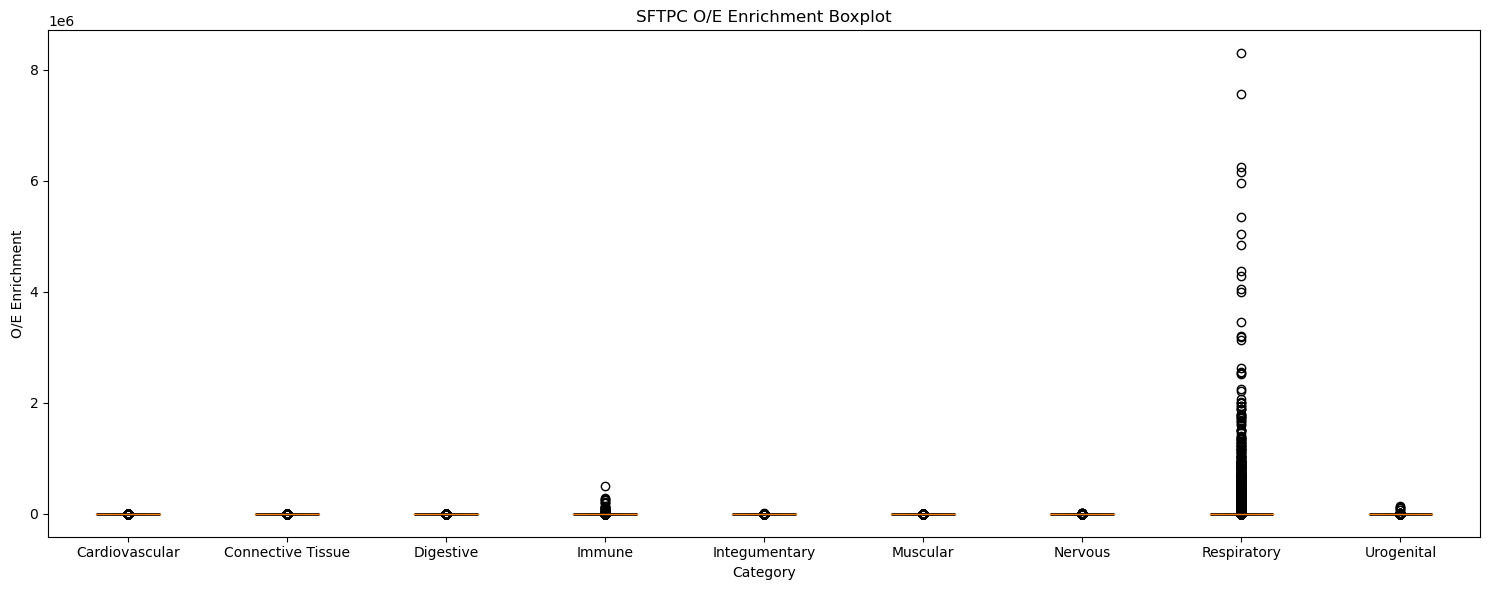

In [137]:
# Plot Indiv. Gene Data (ie. Raw)
def plot_individual_gene_data(matrix, gene_name):
    fig, ax = plt.subplots(figsize=(15, 6))

    positions = np.arange(len(matrix))
    boxprops = dict(linewidth=2)

    bp = ax.boxplot(matrix, positions=positions, widths=0.4, patch_artist=True, boxprops=boxprops)

    ax.set_xticks(positions)
    ax.set_xticklabels(xlabel_system_names)
    ax.set_xlabel("Category")
    ax.set_ylabel("O/E Enrichment")
    ax.set_title(f"{gene_name} O/E Enrichment Boxplot")

    colors = ["lightblue", "lightgreen", "moccasin", "pink"]
    for box, color in zip(bp["boxes"], colors):
        box.set_facecolor(color)

    plt.tight_layout()
    plt.show()
    
plot_individual_gene_data(raw_cat_ooe_matrix, gene_name)

---
# Threshold

In [138]:
# IMPORTANT: WILL NEED TO CHANGE FOR OTHER MATRIXES 

# Extract the indexed row from the raw_matrix, WILL NEED TO CHANGE FOR OTHER MATRIXES
threshold_gene_data = threshold_matrix[gene_index]

threshold_cat_ooe_matrix = get_gene_cat_matrix(threshold_gene_data, category_dict, category_names) # (aka: get_gene_cat_ooe_matrix)
print("Threshold Category OOE Matrix")
print()

Threshold Category OOE Matrix



---
# Corrected

In [139]:
# IMPORTANT: WILL NEED TO CHANGE FOR OTHER MATRIXES 

# Extract the indexed row from the raw_matrix, WILL NEED TO CHANGE FOR OTHER MATRIXES
corrected_gene_data = corrected_matrix[gene_index]

corrected_cat_ooe_matrix = get_gene_cat_matrix(corrected_gene_data, category_dict, category_names) # (aka: get_gene_cat_ooe_matrix)
print("Corrected Category OOE Matrix")
print()

Corrected Category OOE Matrix



---
# QN

In [140]:
# IMPORTANT: WILL NEED TO CHANGE FOR OTHER MATRIXES 

# Extract the indexed row from the raw_matrix, WILL NEED TO CHANGE FOR OTHER MATRIXES
qn_gene_data = qn_matrix[gene_index]

qn_cat_ooe_matrix = get_gene_cat_matrix(qn_gene_data, category_dict, category_names) # (aka: get_gene_cat_ooe_matrix)
print("QN Category OOE Matrix")
print()

QN Category OOE Matrix



---
# ALL 4 MATRIX BOXPLOT - ALL SYSTEMS

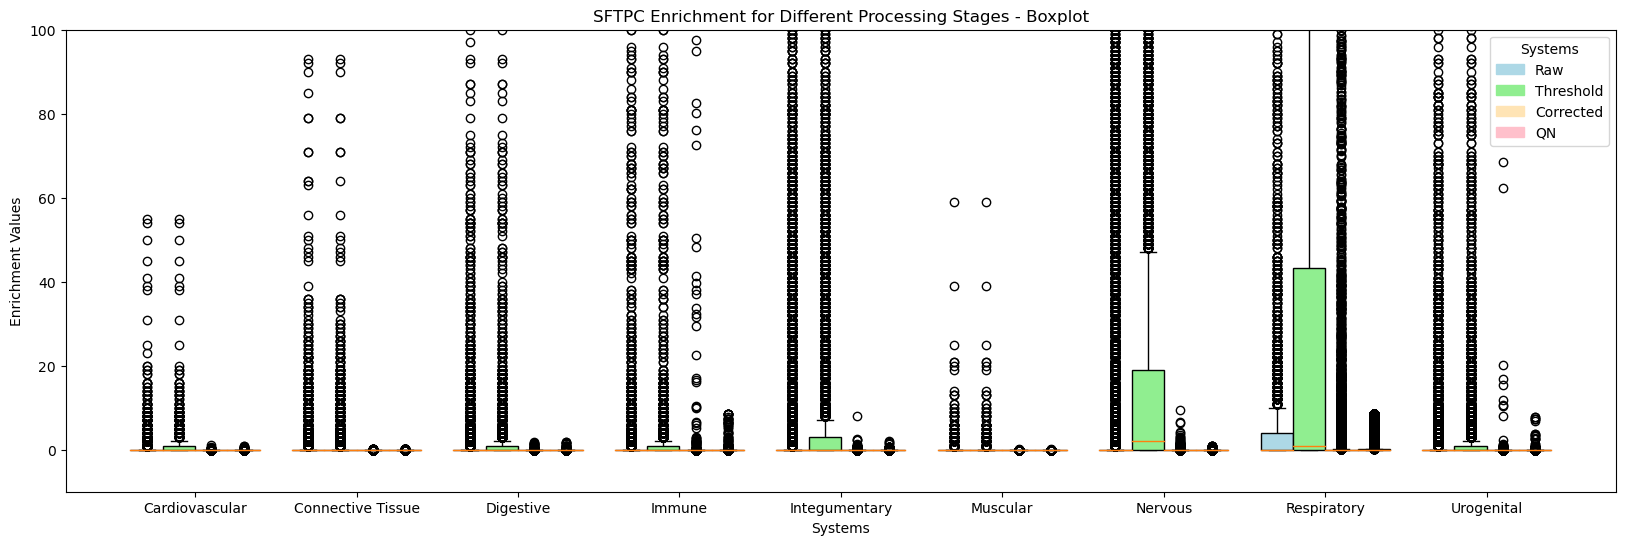

In [143]:
matrix_names = ["Raw", "Threshold", "Corrected", "QN"]
colors = ["lightblue", "lightgreen", "moccasin", "pink"]

def plot_all_systems_data(raw_matrix, threshold_matrix, corrected_matrix, qn_matrix,
                          xlabel_system_names, matrix_names, colors):
    
    fig, ax = plt.subplots(figsize=(20, 6))

    # Iterate over each category and corresponding rows in the matrices
    for i, category in enumerate(xlabel_system_names):
        # Calculate the positions for the boxplots
        positions = [i - 0.3, i - 0.1, i + 0.1, i + 0.3]

        # Extract the values for the current category from the matrices
        raw_values = raw_matrix[i]
        threshold_values = threshold_matrix[i]
        corrected_values = corrected_matrix[i]
        qn_values = qn_matrix[i]

        # Plot the boxplots side by side
        boxplot = ax.boxplot(
            [raw_values, threshold_values, corrected_values, qn_values],
            positions=positions,
            widths=0.2,
            patch_artist=True,
        )

        # Set the facecolor for each boxplot
        for patch, color in zip(boxplot["boxes"], colors):
            patch.set_facecolor(color)

    # Create custom legend handles with associated colors
    legend_handles = [
        mpatches.Patch(color=color, label=system_name)
        for color, system_name in zip(colors, matrix_names)
    ]

    # Set the x-axis tick labels and title
    ax.set_xticks(range(len(xlabel_system_names)))
    ax.set_xticklabels(xlabel_system_names)
    ax.set_xlabel("Systems")

    # Set the y-axis label
    ax.set_ylabel("Enrichment Values")
    
    # Set the y-axis limit
    ax.set_ylim(-10, 100)

    # Display the legend with custom handles and title
    ax.legend(handles=legend_handles, title="Systems", loc="upper right")


    # Set the title
    plt.title(f"{gene_name} Enrichment for Different Processing Stages - Boxplot")

    # Show the plot
    plt.show()

# Call the function to plot the data
plot_all_systems_data(raw_cat_ooe_matrix, threshold_cat_ooe_matrix, corrected_cat_ooe_matrix, 
                      qn_cat_ooe_matrix, xlabel_system_names, matrix_names, colors)


---
# ALL 4 MATRIX BOXPLOT - CARDIOVASCULAR SYSTEM

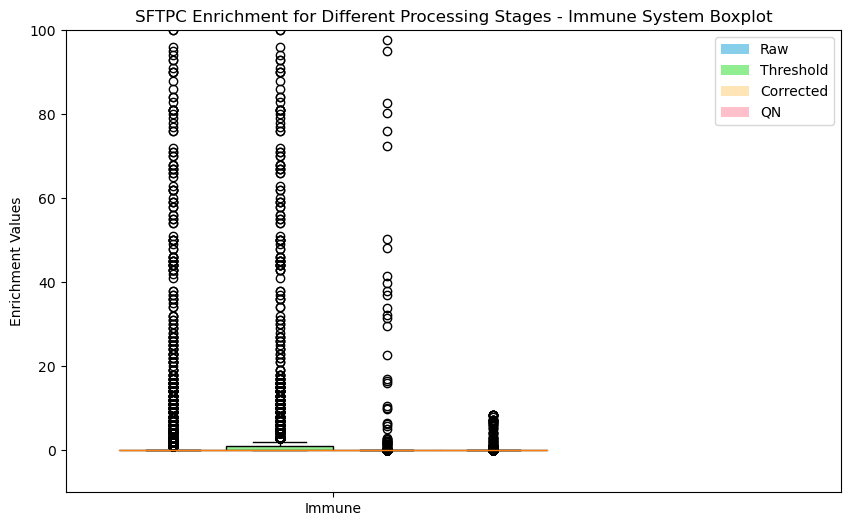

In [142]:
def plot_individual_system_data(raw_matrix, threshold_matrix, corrected_matrix, qn_matrix, 
                                category_dict, 
                                system_idx):
    
    # Extract the first category name and its corresponding values from the category_dict
    category = xlabel_system_names[system_idx]
    data = list(category_dict.values())[system_idx]

    # Extract the first row of the raw_matrix, qn_matrix, threshold_matrix, and corrected_matrix
    category_values_raw = raw_matrix[system_idx]
    category_values_qn = qn_matrix[system_idx]
    category_values_threshold = threshold_matrix[system_idx]
    category_values_corrected = corrected_matrix[system_idx]

    # Set the figure size (increase the width as desired)
    fig, ax = plt.subplots(figsize=(10, 6))

    # Set the width for each boxplot
    width = 0.4

    # Set the positions for the boxplots
    positions_raw = np.array([0])
    positions_threshold = positions_raw + width
    positions_corrected = positions_threshold + width
    positions_qn = positions_corrected + width
    
    # Plot a boxplot for the first category values from raw_matrix
    ax.boxplot(category_values_raw, positions=positions_raw, labels=[category],
               patch_artist=True, boxprops=dict(facecolor='skyblue'), widths=width)

    # Plot a boxplot for the first category values from threshold_matrix
    ax.boxplot(category_values_threshold, positions=positions_threshold, labels=[''],
               patch_artist=True, boxprops=dict(facecolor='lightgreen'), widths=width)

    # Plot a boxplot for the first category values from corrected_matrix
    ax.boxplot(category_values_corrected, positions=positions_corrected, labels=[''],
               patch_artist=True, boxprops=dict(facecolor='moccasin'), widths=width)
    
 # Plot a boxplot for the first category values from qn_matrix
    ax.boxplot(category_values_qn, positions=positions_qn, labels=[''],
               patch_artist=True, boxprops=dict(facecolor='pink'), widths=width)
    
    # Set the x-axis limits
    ax.set_xlim(-width, 2.5)

    # Set the x-axis tick positions and labels
    tick_positions = np.array([width * 1.5])  # Adjust the position for centering
    tick_labels = [category]
    ax.set_xticks(tick_positions)
    ax.set_xticklabels(tick_labels, ha='center')  # Set horizontal alignment to center

    # Set the y-axis label
    ax.set_ylabel('Enrichment Values')
    
    # Set the y-axis limit
    ax.set_ylim(-10, 100)

    # Set the title
    ax.set_title(f"{gene_name} Enrichment for Different Processing Stages - {list(category_dict.keys())[system_idx]} Boxplot")

    # Create custom legend labels for the boxplot colors
    blue_patch = plt.Rectangle((0, 0), 1, 1, fc='skyblue')
    green_patch = plt.Rectangle((0, 0), 1, 1, fc='lightgreen')
    orange_patch = plt.Rectangle((0, 0), 1, 1, fc='moccasin')
    pink_patch = plt.Rectangle((0, 0), 1, 1, fc='pink')
    ax.legend([blue_patch, green_patch, orange_patch, pink_patch], ['Raw',  'Threshold', 'Corrected','QN'])

    # Display the plot
    plt.show()

system_idx = 3 # MASTER USER INPUT

plot_individual_system_data(raw_cat_ooe_matrix, threshold_cat_ooe_matrix, corrected_cat_ooe_matrix, 
                      qn_cat_ooe_matrix, category_dict, system_idx)
